# MScFE 652 Portfolio Management – Group Work Project #2
## Enhanced Implementation with All Recommendations

This notebook implements a comprehensive portfolio optimization analysis including:

- **Mean‑Variance Optimization (MVO)** with various constraints  
- **MVO vs 1/N portfolio** simulation study  
- **Black‑Litterman model** with analyst views  
- **Kelly Criterion** portfolio allocation  

**Author:** Enhanced Implementation  
**Date:** February 2026  

The analysis uses daily data from January 2023 to June 2025 for seven selected stocks.  
All results are saved as CSV files and PNG figures.

**Install Required Libraries**

In [1]:
!pip install yfinance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy import stats
import yfinance as yf
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style for professional visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 89.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 80.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [yfinance]


**Configuration Parameters**

In [2]:
# ============================================================================
# CONFIGURATION SECTION
# ============================================================================

# Project Configuration
TICKERS = ['AAPL', 'NVDA', 'TSLA', 'XOM', 'REGN', 'LLY', 'JPM']
START_DATE = '2023-01-01'
END_DATE = '2025-06-30'
DATA_INTERVAL = '1d'  # Using daily data for better parameter estimation

# Risk-free rate: 4% annual (based on 10-year US Treasury yield as of early 2025)
RISK_FREE_RATE = 0.04

# Part 2: Simulation Configuration
UNIVERSE_20 = [
    # Technology (4)
    'AAPL', 'MSFT', 'GOOGL', 'NVDA',
    # Healthcare (3)
    'JNJ', 'UNH', 'PFE',
    # Financials (3)
    'JPM', 'BAC', 'GS',
    # Consumer (3)
    'AMZN', 'WMT', 'HD',
    # Energy (2)
    'XOM', 'CVX',
    # Industrials (2)
    'CAT', 'BA',
    # Materials (2)
    'LIN', 'APD',
    # Utilities (1)
    'NEE'
]

SIMULATION_START = '2022-01-01'
SIMULATION_END = '2024-12-31'
TRAIN_YEARS = 2
TEST_YEARS = 1
N_SIMULATIONS = 5000
RANDOM_SEED = 42

print("=" * 80)
print("MScFE 652 - PORTFOLIO MANAGEMENT - GROUP WORK PROJECT #2")
print("Enhanced Implementation with All Improvements")
print("=" * 80)
print(f"\nProject Configuration:")
print(f"  Assets: {TICKERS}")
print(f"  Period: {START_DATE} to {END_DATE}")
print(f"  Data Frequency: {DATA_INTERVAL} (daily)")
print(f"  Risk-Free Rate: {RISK_FREE_RATE:.1%}")
print(f"  Simulation Universe: {len(UNIVERSE_20)} assets")
print(f"  Number of Simulations: {N_SIMULATIONS:,}")
print("=" * 80)

MScFE 652 - PORTFOLIO MANAGEMENT - GROUP WORK PROJECT #2
Enhanced Implementation with All Improvements

Project Configuration:
  Assets: ['AAPL', 'NVDA', 'TSLA', 'XOM', 'REGN', 'LLY', 'JPM']
  Period: 2023-01-01 to 2025-06-30
  Data Frequency: 1d (daily)
  Risk-Free Rate: 4.0%
  Simulation Universe: 20 assets
  Number of Simulations: 5,000


**Data Retrieval and Analysis Functions**

In [3]:
# ============================================================================
# PART 1: DATA RETRIEVAL AND ANALYSIS
# ============================================================================

def fetch_portfolio_data(tickers, start_date, end_date, interval='1d'):
    """Fetch historical price data for given tickers from Yahoo Finance."""
    print(f"\n{'='*80}")
    print(f"FETCHING DATA")
    print(f"{'='*80}")
    print(f"Tickers: {tickers}")
    print(f"Period: {start_date} to {end_date}")
    print(f"Interval: {interval}")

    data = yf.download(tickers, start=start_date, end=end_date,
                       interval=interval, progress=False)

    if data.empty:
        raise ValueError("No data retrieved. Check tickers and date range.")

    prices = None
    if isinstance(data.columns, pd.MultiIndex):
        if 'Adj Close' in data.columns.get_level_values(0):
            prices = data['Adj Close']
        elif 'Adj Close' in data.columns.get_level_values(1):
            prices = data.xs('Adj Close', level=1, axis=1)
        else:
            if 'Close' in data.columns.get_level_values(0):
                prices = data['Close']
                print("  Warning: 'Adj Close' not found, using 'Close' prices.")
            elif 'Close' in data.columns.get_level_values(1):
                prices = data.xs('Close', level=1, axis=1)
                print("  Warning: 'Adj Close' not found, using 'Close' prices.")
            else:
                raise KeyError(f"Neither 'Adj Close' nor 'Close' column found.")
    else:
        if 'Adj Close' in data.columns:
            prices = data['Adj Close']
        elif 'Close' in data.columns:
            prices = data['Close']
            print("  Warning: 'Adj Close' not found, using 'Close' prices.")
        else:
            raise KeyError(f"Neither 'Adj Close' nor 'Close' column found.")

    if prices is None or prices.empty:
        raise ValueError("No valid price data could be extracted.")

    if isinstance(prices, pd.Series):
        prices = pd.DataFrame(prices)
        if len(tickers) == 1:
            prices.columns = [tickers[0]]

    prices = prices[[col for col in prices.columns if col in tickers]]
    prices = prices.dropna()

    if prices.empty:
        raise ValueError("No valid price data remaining after dropping NaNs.")

    returns = prices.pct_change().dropna()

    print(f"\nData Retrieved Successfully:")
    print(f"  Periods: {len(prices)} trading days")
    print(f"  Assets: {len(prices.columns)}")
    print(f"  Date Range: {prices.index[0].date()} to {prices.index[-1].date()}")
    print(f"  Returns Shape: {returns.shape}")

    return prices, returns


def analyze_returns(returns, risk_free_rate=0.04):
    """Comprehensive statistical analysis of asset returns."""
    periods_per_year = 252 if len(returns) > 300 else 52
    analysis = {}
    analysis['Mean Returns'] = returns.mean() * periods_per_year
    analysis['Volatility'] = returns.std() * np.sqrt(periods_per_year)
    excess_return = analysis['Mean Returns'] - risk_free_rate
    analysis['Sharpe Ratio'] = excess_return / analysis['Volatility']
    analysis['Skewness'] = returns.skew()
    analysis['Kurtosis'] = returns.kurtosis()
    analysis['Correlation Matrix'] = returns.corr()
    return analysis


def create_summary_table(analysis):
    """Create a professional formatted summary statistics table."""
    summary = pd.DataFrame({
        'Mean Return (Annual)': analysis['Mean Returns'].apply(lambda x: f"{x:.2%}"),
        'Volatility (Annual)': analysis['Volatility'].apply(lambda x: f"{x:.2%}"),
        'Sharpe Ratio': analysis['Sharpe Ratio'].apply(lambda x: f"{x:.3f}"),
        'Skewness': analysis['Skewness'].apply(lambda x: f"{x:.3f}"),
        'Excess Kurtosis': analysis['Kurtosis'].apply(lambda x: f"{x:.3f}")
    })
    return summary


def plot_correlation_heatmap(corr_matrix, title="Asset Correlation Matrix",
                             filename=None, figsize=(10, 8)):
    """Plot correlation matrix as a heatmap."""
    plt.figure(figsize=figsize)
    sns.heatmap(corr_matrix,
                annot=True, fmt='.3f', cmap='coolwarm',
                center=0, square=True, linewidths=1,
                cbar_kws={'label': 'Correlation Coefficient'},
                vmin=-1, vmax=1)
    plt.title(title, fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('')
    plt.ylabel('')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"  Saved: {filename}")
    plt.show()


def print_data_summary(returns, analysis):
    """Print formatted summary statistics to console."""
    print(f"\n{'='*80}")
    print("STEP 0: DATA SUMMARY AND DESCRIPTIVE STATISTICS")
    print(f"{'='*80}")

    summary_table = create_summary_table(analysis)
    print("\nSummary Statistics:")
    print(summary_table.to_string())

    print("\n\nKey Observations:")
    best_sharpe_asset = analysis['Sharpe Ratio'].idxmax()
    best_sharpe_value = analysis['Sharpe Ratio'].max()
    print(f"  • Best Sharpe Ratio: {best_sharpe_asset} ({best_sharpe_value:.3f})")

    highest_vol_asset = analysis['Volatility'].idxmax()
    lowest_vol_asset = analysis['Volatility'].idxmin()
    print(f"  • Highest Volatility: {highest_vol_asset} ({analysis['Volatility'][highest_vol_asset]:.2%})")
    print(f"  • Lowest Volatility: {lowest_vol_asset} ({analysis['Volatility'][lowest_vol_asset]:.2%})")

    corr_matrix = analysis['Correlation Matrix']
    upper_triangle = corr_matrix.where(np.triu(np.ones_like(corr_matrix, dtype=bool), k=1))
    max_corr = upper_triangle.max().max()
    min_corr = upper_triangle.min().min()
    avg_corr = upper_triangle.stack().mean()
    print(f"  • Average Correlation: {avg_corr:.3f}")
    print(f"  • Correlation Range: [{min_corr:.3f}, {max_corr:.3f}]")

    positive_skew = (analysis['Skewness'] > 0.5).sum()
    negative_skew = (analysis['Skewness'] < -0.5).sum()
    if positive_skew > 0:
        print(f"  • {positive_skew} asset(s) show positive skewness (right tail risk)")
    if negative_skew > 0:
        print(f"  • {negative_skew} asset(s) show negative skewness (left tail risk)")

    fat_tails = (analysis['Kurtosis'] > 3).sum()
    if fat_tails > 0:
        print(f"  • {fat_tails} asset(s) exhibit fat tails (excess kurtosis > 3)")

**Mean‑Variance Optimization Functions**

In [4]:
# ============================================================================
# PART 1: MEAN-VARIANCE OPTIMIZATION (STEPS 1-3)
# ============================================================================

def portfolio_performance(weights, mean_returns, cov_matrix, risk_free_rate=0.04):
    """Calculate portfolio performance metrics."""
    portfolio_return = np.dot(weights, mean_returns)
    portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
    portfolio_volatility = np.sqrt(portfolio_variance)
    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility
    return {
        'return': portfolio_return,
        'volatility': portfolio_volatility,
        'sharpe': sharpe_ratio
    }


def negative_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate):
    """Calculate negative Sharpe ratio for minimization."""
    perf = portfolio_performance(weights, mean_returns, cov_matrix, risk_free_rate)
    return -perf['sharpe']


def optimize_portfolio(mean_returns, cov_matrix, risk_free_rate=0.04,
                      allow_short=False, max_weight=1.0):
    """Optimize portfolio to maximize Sharpe ratio."""
    n_assets = len(mean_returns)

    if isinstance(mean_returns, pd.Series):
        mean_returns = mean_returns.values
    if isinstance(cov_matrix, pd.DataFrame):
        cov_matrix = cov_matrix.values

    initial_weights = np.array([1.0 / n_assets] * n_assets)

    constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]

    if allow_short:
        bounds = tuple((-2.0, 2.0) for _ in range(n_assets))
    else:
        bounds = tuple((0.0, max_weight) for _ in range(n_assets))

    result = minimize(
        fun=negative_sharpe_ratio,
        x0=initial_weights,
        args=(mean_returns, cov_matrix, risk_free_rate),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints,
        options={'maxiter': 1000, 'ftol': 1e-9}
    )

    optimal_weights = result.x
    perf = portfolio_performance(optimal_weights, mean_returns,
                                 cov_matrix, risk_free_rate)

    return {
        'weights': optimal_weights,
        'return': perf['return'],
        'volatility': perf['volatility'],
        'sharpe': perf['sharpe'],
        'success': result.success,
        'message': result.message
    }


def create_comparison_table(results_dict, asset_names):
    """Create a comprehensive comparison table for different portfolio strategies."""
    weights_data = {}
    for strategy, result in results_dict.items():
        weights_data[strategy] = result['weights']

    weights_df = pd.DataFrame(weights_data, index=asset_names)
    weights_df.loc['Sum'] = weights_df.sum()
    weights_df.loc['Long Exposure'] = weights_df[weights_df > 0].sum()
    weights_df.loc['Short Exposure'] = weights_df[weights_df < 0].sum()
    weights_df.loc['Gross Leverage'] = weights_df.abs().sum()

    metrics_data = {
        'Expected Return (Annual)': [f"{r['return']:.2%}" for r in results_dict.values()],
        'Volatility (Annual)': [f"{r['volatility']:.2%}" for r in results_dict.values()],
        'Sharpe Ratio': [f"{r['sharpe']:.4f}" for r in results_dict.values()],
    }
    metrics_df = pd.DataFrame(metrics_data, index=list(results_dict.keys()))

    return weights_df, metrics_df


def plot_efficient_frontier(mean_returns, cov_matrix, risk_free_rate=0.04,
                           optimal_portfolios=None, n_portfolios=100,
                           filename=None):
    """Plot the efficient frontier and mark optimal portfolios."""
    n_assets = len(mean_returns)

    if isinstance(mean_returns, pd.Series):
        mean_returns_np = mean_returns.values
        cov_matrix_np = cov_matrix.values
    else:
        mean_returns_np = mean_returns
        cov_matrix_np = cov_matrix

    frontier_returns = []
    frontier_volatilities = []
    frontier_sharpes = []

    min_return = mean_returns_np.min()
    max_return = mean_returns_np.max()
    target_returns = np.linspace(min_return, max_return * 1.2, n_portfolios)

    for target in target_returns:
        try:
            def portfolio_volatility(weights):
                return np.sqrt(np.dot(weights.T, np.dot(cov_matrix_np, weights)))

            constraints = [
                {'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
                {'type': 'eq', 'fun': lambda w: np.dot(w, mean_returns_np) - target}
            ]
            bounds = tuple((0.0, 1.0) for _ in range(n_assets))
            initial = np.array([1.0 / n_assets] * n_assets)

            result = minimize(
                portfolio_volatility,
                initial,
                method='SLSQP',
                bounds=bounds,
                constraints=constraints,
                options={'maxiter': 500, 'ftol': 1e-8}
            )

            if result.success:
                vol = portfolio_volatility(result.x)
                ret = np.dot(result.x, mean_returns_np)
                sharpe = (ret - risk_free_rate) / vol
                frontier_returns.append(ret)
                frontier_volatilities.append(vol)
                frontier_sharpes.append(sharpe)
        except:
            continue

    fig, ax = plt.subplots(figsize=(12, 8))
    scatter = ax.scatter(frontier_volatilities, frontier_returns,
                        c=frontier_sharpes, cmap='viridis',
                        s=30, alpha=0.6, edgecolors='none')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Sharpe Ratio', rotation=270, labelpad=20, fontsize=10)

    if optimal_portfolios:
        markers = ['o', '^', 's', '*', 'D', 'P']
        colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']
        for i, (name, result) in enumerate(optimal_portfolios.items()):
            ax.scatter(result['volatility'], result['return'],
                      s=300, marker=markers[i % len(markers)],
                      color=colors[i % len(colors)],
                      edgecolors='black', linewidths=2,
                      label=name, zorder=5, alpha=0.9)

    if optimal_portfolios and 'Step 1: No Short Selling' in optimal_portfolios:
        max_sharpe = optimal_portfolios['Step 1: No Short Selling']
        cml_x = np.linspace(0, max(frontier_volatilities) * 1.1, 100)
        cml_y = risk_free_rate + max_sharpe['sharpe'] * cml_x
        ax.plot(cml_x, cml_y, 'r--', linewidth=2, label='Capital Market Line', alpha=0.7)

    ax.scatter(0, risk_free_rate, s=200, marker='*',
              color='gold', edgecolors='black', linewidths=2,
              label=f'Risk-Free Rate ({risk_free_rate:.1%})', zorder=5)

    ax.set_xlabel('Volatility (Annual Standard Deviation)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Expected Return (Annual)', fontsize=12, fontweight='bold')
    ax.set_title('Efficient Frontier with Optimal Portfolios', fontsize=14, fontweight='bold', pad=20)
    ax.legend(loc='best', fontsize=10, framealpha=0.95)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    plt.tight_layout()

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"  Saved: {filename}")
    plt.show()

**Fetch Data and Initial Analysis**


################################################################################
# PART 1: MEAN-VARIANCE OPTIMIZATION
################################################################################

FETCHING DATA
Tickers: ['AAPL', 'NVDA', 'TSLA', 'XOM', 'REGN', 'LLY', 'JPM']
Period: 2023-01-01 to 2025-06-30
Interval: 1d

Data Retrieved Successfully:
  Periods: 623 trading days
  Assets: 7
  Date Range: 2023-01-03 to 2025-06-27
  Returns Shape: (622, 7)

STEP 0: DATA SUMMARY AND DESCRIPTIVE STATISTICS

Summary Statistics:
       Mean Return (Annual) Volatility (Annual) Sharpe Ratio Skewness Excess Kurtosis
Ticker                                                                               
AAPL                 23.21%              26.38%        0.728    0.843          14.045
JPM                  35.96%              23.71%        1.348    0.213          10.115
LLY                  36.70%              32.85%        0.996    0.740           9.733
NVDA                111.31%              

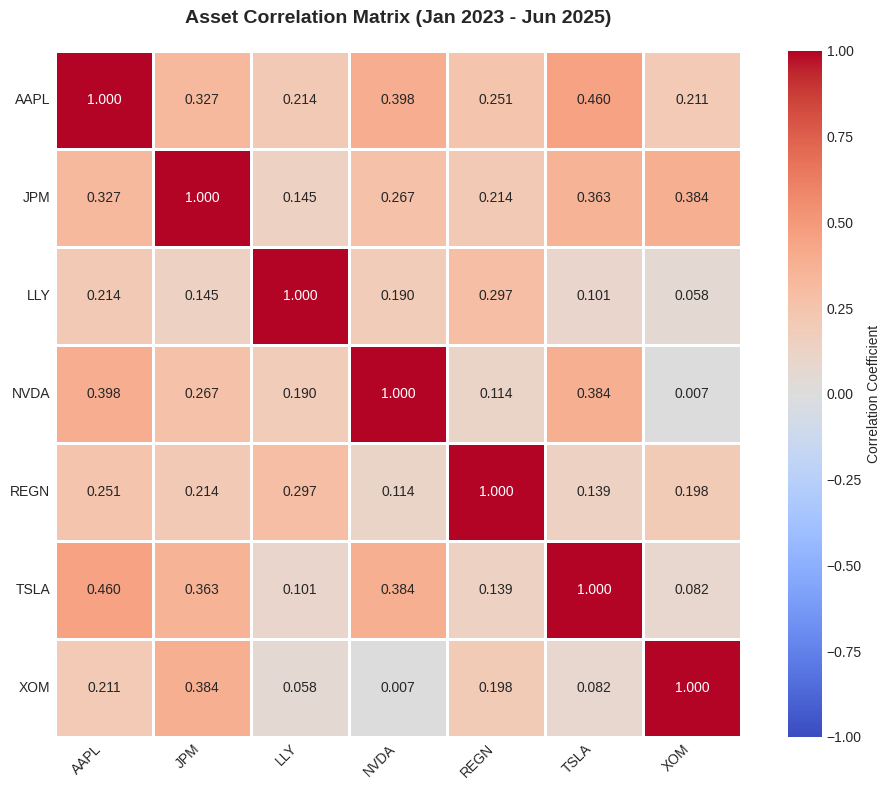

In [5]:
# ============================================================================
# PART 1: DATA COLLECTION AND MEAN-VARIANCE OPTIMIZATION (Execution)
# ============================================================================

print("\n" + "#"*80)
print("# PART 1: MEAN-VARIANCE OPTIMIZATION")
print("#"*80)

# Fetch data
prices, returns = fetch_portfolio_data(TICKERS, START_DATE, END_DATE, DATA_INTERVAL)

# Analyze returns
analysis = analyze_returns(returns, RISK_FREE_RATE)

# Print summary
print_data_summary(returns, analysis)

# Plot correlation heatmap
print("\nGenerating correlation heatmap...")
plot_correlation_heatmap(analysis['Correlation Matrix'],
                        title="Asset Correlation Matrix (Jan 2023 - Jun 2025)",
                        filename="correlation_heatmap.png")

# Prepare for optimization
mean_returns = analysis['Mean Returns']
cov_matrix = returns.cov() * 252  # Annualized covariance

**Steps 1‑3 – Optimize with Different Constraints**

In [6]:
# ========================================================================
# STEPS 1-3: Portfolio Optimization with Different Constraints
# ========================================================================

print(f"\n{'='*80}")
print("PORTFOLIO OPTIMIZATION: STEPS 1-3")
print(f"{'='*80}")

# Step 1: No short selling
print("\nStep 1: Optimizing portfolio (no short selling)...")
step1_result = optimize_portfolio(mean_returns, cov_matrix, RISK_FREE_RATE,
                                 allow_short=False, max_weight=1.0)
print(f"  Success: {step1_result['success']}")
print(f"  Return: {step1_result['return']:.2%}")
print(f"  Volatility: {step1_result['volatility']:.2%}")
print(f"  Sharpe: {step1_result['sharpe']:.4f}")

# Step 2: No short selling + 20% max weight
print("\nStep 2: Optimizing portfolio (no short selling, 20% max per asset)...")
step2_result = optimize_portfolio(mean_returns, cov_matrix, RISK_FREE_RATE,
                                 allow_short=False, max_weight=0.20)
print(f"  Success: {step2_result['success']}")
print(f"  Return: {step2_result['return']:.2%}")
print(f"  Volatility: {step2_result['volatility']:.2%}")
print(f"  Sharpe: {step2_result['sharpe']:.4f}")

# Step 3: Short selling allowed
print("\nStep 3: Optimizing portfolio (short selling allowed)...")
step3_result = optimize_portfolio(mean_returns, cov_matrix, RISK_FREE_RATE,
                                 allow_short=True, max_weight=2.0)
print(f"  Success: {step3_result['success']}")
print(f"  Return: {step3_result['return']:.2%}")
print(f"  Volatility: {step3_result['volatility']:.2%}")
print(f"  Sharpe: {step3_result['sharpe']:.4f}")


PORTFOLIO OPTIMIZATION: STEPS 1-3

Step 1: Optimizing portfolio (no short selling)...
  Success: True
  Return: 65.02%
  Volatility: 27.08%
  Sharpe: 2.2528

Step 2: Optimizing portfolio (no short selling, 20% max per asset)...
  Success: True
  Return: 45.58%
  Volatility: 21.02%
  Sharpe: 1.9782

Step 3: Optimizing portfolio (short selling allowed)...
  Success: True
  Return: 111.94%
  Volatility: 43.45%
  Sharpe: 2.4842


**MVO vs 1/N Simulation Functions**

In [7]:
# ============================================================================
# PART 2: MVO VS 1/N SIMULATION
# ============================================================================

def simulate_mvo_vs_1n(universe_tickers, start_date, end_date,
                      train_years=2, test_years=1, n_simulations=5000,
                      n_assets_per_portfolio=5, risk_free_rate=0.04,
                      random_seed=42):
    """Simulate MVO vs 1/N portfolio performance comparison."""
    print(f"\n{'='*80}")
    print("PART 2: MVO VS 1/N SIMULATION")
    print(f"{'='*80}")
    print(f"Simulation Parameters:\n  Universe Size: {len(universe_tickers)} assets")
    print(f"  Assets per Portfolio: {n_assets_per_portfolio}")
    print(f"  Training Period: {train_years} years")
    print(f"  Testing Period: {test_years} year")
    print(f"  Number of Simulations: {n_simulations:,}")
    print(f"  Random Seed: {random_seed}")

    np.random.seed(random_seed)

    print(f"\nFetching data for {len(universe_tickers)} assets...")
    try:
        universe_data = yf.download(universe_tickers, start=start_date,
                                   end=end_date, progress=False)
        if universe_data.empty:
            raise ValueError("No data retrieved for simulation universe.")

        universe_prices = None
        if isinstance(universe_data.columns, pd.MultiIndex):
            if 'Adj Close' in universe_data.columns.get_level_values(0):
                universe_prices = universe_data['Adj Close']
            elif 'Adj Close' in universe_data.columns.get_level_values(1):
                universe_prices = universe_data.xs('Adj Close', level=1, axis=1)
            else:
                if 'Close' in universe_data.columns.get_level_values(0):
                    universe_prices = universe_data['Close']
                    print("  Warning: 'Adj Close' not found for simulation data, using 'Close' prices.")
                elif 'Close' in universe_data.columns.get_level_values(1):
                    universe_prices = universe_data.xs('Close', level=1, axis=1)
                    print("  Warning: 'Adj Close' not found for simulation data, using 'Close' prices.")
                else:
                    raise KeyError(f"Neither 'Adj Close' nor 'Close' column found.")
        else:
            if 'Adj Close' in universe_data.columns:
                universe_prices = universe_data['Adj Close']
            elif 'Close' in universe_data.columns:
                universe_prices = universe_data['Close']
                print("  Warning: 'Adj Close' not found for simulation data, using 'Close' prices.")
            else:
                raise KeyError(f"Neither 'Adj Close' nor 'Close' column found.")

        if universe_prices is None or universe_prices.empty:
            raise ValueError("No valid price data could be extracted for simulation universe.")

        if isinstance(universe_prices, pd.Series):
            universe_prices = pd.DataFrame(universe_prices)
            if len(universe_tickers) == 1:
                universe_prices.columns = [universe_tickers[0]]

        universe_prices = universe_prices[[col for col in universe_prices.columns if col in universe_tickers]].dropna()
        if universe_prices.empty:
            raise ValueError("No valid price data remaining for simulation universe after filtering.")

        universe_returns = universe_prices.pct_change().dropna()

    except Exception as e:
        print(f"Error fetching or processing simulation data: {e}")
        return None

    total_days = len(universe_returns)
    train_days = int(total_days * (train_years / (train_years + test_years)))
    split_date = universe_returns.index[train_days]
    print(f"\nData Split:\n  Training: {universe_returns.index[0].date()} to {split_date.date()} ({train_days} days)")
    print(f"  Testing: {split_date.date()} to {universe_returns.index[-1].date()} ({total_days - train_days} days)")

    mvo_returns = []
    naive_returns = []
    selected_assets_list = []

    print(f"\nRunning {n_simulations:,} simulations...")
    print("Progress: ", end='')

    for i in range(n_simulations):
        if (i + 1) % 500 == 0:
            print(f"{i+1:,}...", end='', flush=True)

        selected_assets = np.random.choice(universe_tickers,
                                          size=n_assets_per_portfolio,
                                          replace=False)
        asset_returns = universe_returns[list(selected_assets)]

        if len(asset_returns) <= train_days + 1:
            continue

        train_returns = asset_returns.iloc[:train_days]
        test_returns = asset_returns.iloc[train_days:]

        if train_returns.empty or test_returns.empty:
            continue

        mean_returns = train_returns.mean() * 252
        cov_matrix = train_returns.cov() * 252

        try:
            mvo_result = optimize_portfolio(mean_returns, cov_matrix,
                                           risk_free_rate=risk_free_rate,
                                           allow_short=False, max_weight=1.0)
            mvo_weights = mvo_result['weights']
        except Exception:
            mvo_weights = np.array([1.0 / n_assets_per_portfolio] * n_assets_per_portfolio)

        naive_weights = np.array([1.0 / n_assets_per_portfolio] * n_assets_per_portfolio)

        mvo_portfolio_returns = test_returns @ mvo_weights
        naive_portfolio_returns = test_returns @ naive_weights

        if not test_returns.empty and len(test_returns) > 0:
            mvo_annual_return = (1 + mvo_portfolio_returns).prod() ** (252 / len(test_returns)) - 1
            naive_annual_return = (1 + naive_portfolio_returns).prod() ** (252 / len(test_returns)) - 1

            mvo_returns.append(mvo_annual_return)
            naive_returns.append(naive_annual_return)
            selected_assets_list.append(','.join(selected_assets))

    print(" Done!")

    results_df = pd.DataFrame({
        'MVO_Return': mvo_returns,
        '1/N_Return': naive_returns,
        'Selected_Assets': selected_assets_list
    })

    if results_df.empty:
        print("No successful simulations completed. Check data availability and parameters.")
        return None

    print(f"\nSimulation Complete!\n  Total Successful Simulations: {len(results_df):,}")
    print(f"  MVO Mean Return: {results_df['MVO_Return'].mean():.2%}")
    print(f"  1/N Mean Return: {results_df['1/N_Return'].mean():.2%}")

    return results_df


def analyze_simulation_results(results_df):
    """Comprehensive statistical analysis of MVO vs 1/N simulation results."""
    mvo_returns = results_df['MVO_Return']
    naive_returns = results_df['1/N_Return']

    stats_data = {
        'Strategy': ['MVO', '1/N', 'Difference'],
        'Mean Return': [
            mvo_returns.mean(),
            naive_returns.mean(),
            mvo_returns.mean() - naive_returns.mean()
        ],
        'Median Return': [
            mvo_returns.median(),
            naive_returns.median(),
            mvo_returns.median() - naive_returns.median()
        ],
        'Std Dev': [
            mvo_returns.std(),
            naive_returns.std(),
            (mvo_returns - naive_returns).std()
        ],
        'Sharpe Ratio': [
            mvo_returns.mean() / mvo_returns.std(),
            naive_returns.mean() / naive_returns.std(),
            np.nan
        ],
        'Skewness': [
            mvo_returns.skew(),
            naive_returns.skew(),
            (mvo_returns - naive_returns).skew()
        ],
        'Kurtosis': [
            mvo_returns.kurtosis(),
            naive_returns.kurtosis(),
            (mvo_returns - naive_returns).kurtosis()
        ],
        'Min Return': [
            mvo_returns.min(),
            naive_returns.min(),
            (mvo_returns - naive_returns).min()
        ],
        'Max Return': [
            mvo_returns.max(),
            naive_returns.max(),
            (mvo_returns - naive_returns).max()
        ],
        '5th Percentile': [
            mvo_returns.quantile(0.05),
            naive_returns.quantile(0.05),
            (mvo_returns - naive_returns).quantile(0.05)
        ],
        '95th Percentile': [
            mvo_returns.quantile(0.95),
            naive_returns.quantile(0.95),
            (mvo_returns - naive_returns).quantile(0.95)
        ],
        'Win Rate': [
            (mvo_returns > naive_returns).sum() / len(mvo_returns),
            (naive_returns > mvo_returns).sum() / len(naive_returns),
            np.nan
        ]
    }

    analysis_df = pd.DataFrame(stats_data)

    print(f"\n{'='*80}")
    print("STATISTICAL HYPOTHESIS TESTING")
    print(f"{'='*80}")

    t_stat, t_pvalue = stats.ttest_rel(mvo_returns, naive_returns)
    print(f"\nPaired t-test:\n  H0: Mean(MVO) = Mean(1/N)\n  H1: Mean(MVO) ≠ Mean(1/N)")
    print(f"  t-statistic: {t_stat:.4f}\n  p-value: {t_pvalue:.6f}")
    if t_pvalue < 0.05:
        print(f"  * SIGNIFICANT: Reject H0 at 5% level")
        print(f"  -> MVO {'significantly outperforms' if t_stat > 0 else 'significantly underperforms'} 1/N")
    else:
        print(f"  ! NOT SIGNIFICANT: Fail to reject H0")

    w_stat, w_pvalue = stats.wilcoxon(mvo_returns - naive_returns)
    print(f"\nWilcoxon Signed-Rank Test:\n  Statistic: {w_stat:.4f}\n  p-value: {w_pvalue:.6f}")
    if w_pvalue < 0.05:
        print(f"  * SIGNIFICANT: Difference detected at 5% level")
    else:
        print(f"  ! NOT SIGNIFICANT: No robust difference detected")

    f_stat = mvo_returns.var() / naive_returns.var()
    f_pvalue = 2 * min(stats.f.cdf(f_stat, len(mvo_returns)-1, len(naive_returns)-1),
                       1 - stats.f.cdf(f_stat, len(mvo_returns)-1, len(naive_returns)-1))
    print(f"\nVariance Ratio Test:\n  F-statistic: {f_stat:.4f}\n  p-value: {f_pvalue:.6f}")
    if f_pvalue < 0.05:
        print(f"  * SIGNIFICANT: Variances differ significantly")
        if f_stat > 1:
            print(f"  -> MVO has higher volatility")
        else:
            print(f"  -> 1/N has higher volatility")
    else:
        print(f"  ! NOT SIGNIFICANT: Variances not significantly different")

    test_results = {
        't_stat': t_stat, 't_pvalue': t_pvalue,
        'w_stat': w_stat, 'w_pvalue': w_pvalue,
        'f_stat': f_stat, 'f_pvalue': f_pvalue
    }
    return analysis_df, test_results


def plot_simulation_results(results_df, filename=None):
    """Create comprehensive visualization of simulation results."""
    mvo_returns = results_df['MVO_Return']
    naive_returns = results_df['1/N_Return']

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('MVO vs 1/N Portfolio Simulation Results (5,000 Iterations)',
                 fontsize=16, fontweight='bold', y=0.995)

    # 1. Histogram
    axes[0, 0].hist(mvo_returns, bins=60, alpha=0.6, label='MVO',
                    color='steelblue', density=True, edgecolor='black', linewidth=0.5)
    axes[0, 0].hist(naive_returns, bins=60, alpha=0.6, label='1/N',
                    color='coral', density=True, edgecolor='black', linewidth=0.5)
    axes[0, 0].axvline(mvo_returns.mean(), color='blue',
                      linestyle='--', linewidth=2.5, label=f'MVO Mean: {mvo_returns.mean():.2%}')
    axes[0, 0].axvline(naive_returns.mean(), color='red',
                      linestyle='--', linewidth=2.5, label=f'1/N Mean: {naive_returns.mean():.2%}')
    axes[0, 0].set_xlabel('Annual Return', fontsize=11, fontweight='bold')
    axes[0, 0].set_ylabel('Density', fontsize=11, fontweight='bold')
    axes[0, 0].set_title('Return Distributions', fontsize=12, fontweight='bold')
    axes[0, 0].legend(fontsize=9, loc='best')
    axes[0, 0].grid(True, alpha=0.3, linestyle='--')
    axes[0, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

    # 2. CDF
    sorted_mvo = np.sort(mvo_returns)
    sorted_naive = np.sort(naive_returns)
    cdf_y = np.linspace(0, 1, len(sorted_mvo))
    axes[0, 1].plot(sorted_mvo, cdf_y, label='MVO', linewidth=2.5, color='steelblue')
    axes[0, 1].plot(sorted_naive, cdf_y, label='1/N', linewidth=2.5, color='coral')
    axes[0, 1].axvline(mvo_returns.median(), color='blue',
                      linestyle=':', linewidth=2, alpha=0.7,
                      label=f'MVO Median: {mvo_returns.median():.2%}')
    axes[0, 1].axvline(naive_returns.median(), color='red',
                      linestyle=':', linewidth=2, alpha=0.7,
                      label=f'1/N Median: {naive_returns.median():.2%}')
    axes[0, 1].set_xlabel('Annual Return', fontsize=11, fontweight='bold')
    axes[0, 1].set_ylabel('Cumulative Probability', fontsize=11, fontweight='bold')
    axes[0, 1].set_title('Cumulative Distribution Functions', fontsize=12, fontweight='bold')
    axes[0, 1].legend(fontsize=9, loc='best')
    axes[0, 1].grid(True, alpha=0.3, linestyle='--')
    axes[0, 1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

    # 3. Q-Q Plot
    axes[1, 0].scatter(sorted_naive, sorted_mvo, alpha=0.5, s=20, color='purple')
    min_val = min(sorted_naive.min(), sorted_mvo.min())
    max_val = max(sorted_naive.max(), sorted_mvo.max())
    axes[1, 0].plot([min_val, max_val], [min_val, max_val],
                   'r--', linewidth=2.5, label='45° Line', alpha=0.8)
    axes[1, 0].set_xlabel('1/N Returns (sorted)', fontsize=11, fontweight='bold')
    axes[1, 0].set_ylabel('MVO Returns (sorted)', fontsize=11, fontweight='bold')
    axes[1, 0].set_title('Quantile-Quantile (Q-Q) Plot', fontsize=12, fontweight='bold')
    axes[1, 0].legend(fontsize=9, loc='best')
    axes[1, 0].grid(True, alpha=0.3, linestyle='--')
    axes[1, 0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    axes[1, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

    # 4. Rolling win rate
    window = 100
    win_indicator = (mvo_returns > naive_returns).astype(int)
    rolling_win_rate = pd.Series(win_indicator.values).rolling(window).mean()
    axes[1, 1].plot(rolling_win_rate.index, rolling_win_rate.values * 100,
                   linewidth=2, color='darkgreen', label=f'MVO Win Rate (rolling {window})')
    axes[1, 1].axhline(50, color='red', linestyle='--', linewidth=2.5,
                      label='50% Baseline', alpha=0.8)
    axes[1, 1].fill_between(rolling_win_rate.index, 50, rolling_win_rate.values * 100,
                           where=(rolling_win_rate.values * 100 >= 50),
                           alpha=0.3, color='green', label='MVO Outperforms')
    axes[1, 1].fill_between(rolling_win_rate.index, 50, rolling_win_rate.values * 100,
                           where=(rolling_win_rate.values * 100 < 50),
                           alpha=0.3, color='red', label='1/N Outperforms')
    axes[1, 1].set_xlabel('Simulation Number', fontsize=11, fontweight='bold')
    axes[1, 1].set_ylabel('MVO Win Rate (%)', fontsize=11, fontweight='bold')
    axes[1, 1].set_title(f'Rolling Win Rate (MVO vs 1/N)', fontsize=12, fontweight='bold')
    axes[1, 1].legend(fontsize=9, loc='best')
    axes[1, 1].grid(True, alpha=0.3, linestyle='--')
    axes[1, 1].set_ylim([0, 100])
    overall_win_rate = (mvo_returns > naive_returns).sum() / len(mvo_returns) * 100
    axes[1, 1].text(0.98, 0.02, f'Overall MVO Win Rate: {overall_win_rate:.1f}%',
                   transform=axes[1, 1].transAxes,
                   fontsize=11, fontweight='bold',
                   verticalalignment='bottom', horizontalalignment='right',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"  Saved: {filename}")
    plt.show()

**Run MVO vs 1/N Simulation**


################################################################################
# PART 2: MVO VS 1/N SIMULATION STUDY
################################################################################

PART 2: MVO VS 1/N SIMULATION
Simulation Parameters:
  Universe Size: 20 assets
  Assets per Portfolio: 5
  Training Period: 2 years
  Testing Period: 1 year
  Number of Simulations: 5,000
  Random Seed: 42

Fetching data for 20 assets...

Data Split:
  Training: 2022-01-04 to 2024-01-02 (500 days)
  Testing: 2024-01-02 to 2024-12-30 (251 days)

Running 5,000 simulations...
Progress: 500...1,000...1,500...2,000...2,500...3,000...3,500...4,000...4,500...5,000... Done!

Simulation Complete!
  Total Successful Simulations: 5,000
  MVO Mean Return: 33.78%
  1/N Mean Return: 26.05%

STATISTICAL HYPOTHESIS TESTING

Paired t-test:
  H0: Mean(MVO) = Mean(1/N)
  H1: Mean(MVO) ≠ Mean(1/N)
  t-statistic: 14.5282
  p-value: 0.000000
  * SIGNIFICANT: Reject H0 at 5% level
  -> MVO significantly outpe

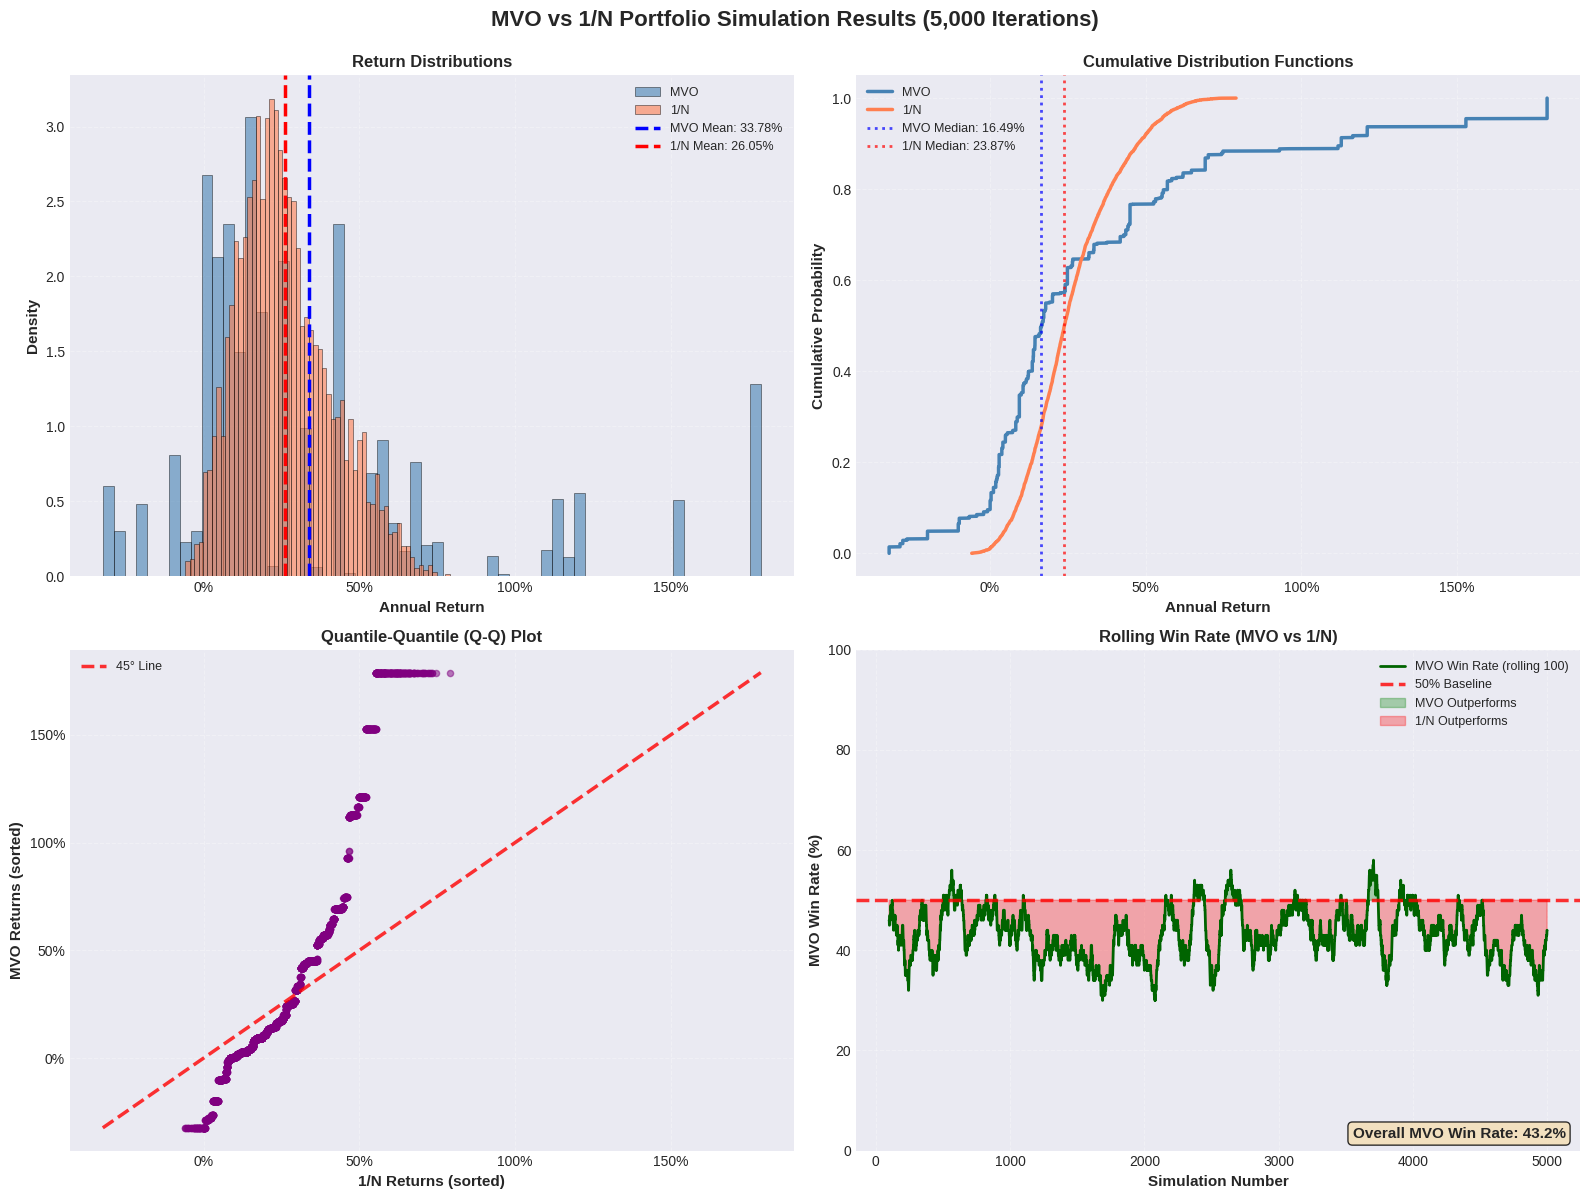


CONCLUSIONS: MVO VS 1/N

Performance Summary:
  • MVO Average Return: 33.78%
  • 1/N Average Return: 26.05%
  • Difference: +7.73%
  • MVO Win Rate: 43.2%

* MVO significantly outperforms 1/N (p-value: 0.000000)

When to prefer 1/N:
  • High estimation error in expected returns
  • Short time series
  • Need for simplicity
  • Avoiding overfitting

When to prefer MVO:
  • Strong signal in historical returns
  • Longer time series
  • Sophisticated risk management
  • Can incorporate views (Black-Litterman)


In [8]:
# ========================================================================
# PART 2: MVO VS 1/N SIMULATION (Execution)
# ========================================================================

print("\n" + "#"*80)
print("# PART 2: MVO VS 1/N SIMULATION STUDY")
print("#"*80)

simulation_results = simulate_mvo_vs_1n(
    UNIVERSE_20,
    SIMULATION_START,
    SIMULATION_END,
    train_years=TRAIN_YEARS,
    test_years=TEST_YEARS,
    n_simulations=N_SIMULATIONS,
    n_assets_per_portfolio=5,
    risk_free_rate=RISK_FREE_RATE,
    random_seed=RANDOM_SEED
)

if simulation_results is not None:
    analysis_df, test_results = analyze_simulation_results(simulation_results)
    print("\n\nStatistical Summary:")
    print(analysis_df.to_string(index=False))

    simulation_results.to_csv('mvo_vs_1n_simulation_results.csv', index=False)
    analysis_df.to_csv('mvo_vs_1n_statistical_analysis.csv', index=False)
    print("\n  Saved: mvo_vs_1n_simulation_results.csv")
    print("  Saved: mvo_vs_1n_statistical_analysis.csv")

    print("\nGenerating simulation visualizations...")
    plot_simulation_results(simulation_results,
                          filename="mvo_vs_1n_comprehensive_analysis.png")

    print(f"\n{'='*80}")
    print("CONCLUSIONS: MVO VS 1/N")
    print(f"{'='*80}")
    mvo_mean = simulation_results['MVO_Return'].mean()
    naive_mean = simulation_results['1/N_Return'].mean()
    win_rate = (simulation_results['MVO_Return'] > simulation_results['1/N_Return']).mean()
    print(f"\nPerformance Summary:\n  • MVO Average Return: {mvo_mean:.2%}\n  • 1/N Average Return: {naive_mean:.2%}")
    print(f"  • Difference: {mvo_mean - naive_mean:+.2%}\n  • MVO Win Rate: {win_rate:.1%}")

    if test_results['t_pvalue'] < 0.05:
        print(f"\n* MVO {'significantly outperforms' if mvo_mean > naive_mean else 'significantly underperforms'} 1/N (p-value: {test_results['t_pvalue']:.6f})")
    else:
        print(f"\n! No statistically significant difference between MVO and 1/N (p-value: {test_results['t_pvalue']:.6f})")

    print("\nWhen to prefer 1/N:\n  • High estimation error in expected returns\n  • Short time series\n  • Need for simplicity\n  • Avoiding overfitting")
    print("\nWhen to prefer MVO:\n  • Strong signal in historical returns\n  • Longer time series\n  • Sophisticated risk management\n  • Can incorporate views (Black-Litterman)")

**Black‑Litterman Functions**

In [9]:
# ============================================================================
# PART 3: BLACK-LITTERMAN MODEL
# ============================================================================

def formulate_views():
    """Formulate analyst views for the 7 assets with sources and rationale."""
    views = {
        'AAPL': {
            'type': 'absolute',
            'return': 0.15,
            'confidence': 0.6,
            'rationale': 'Strong iPhone 16 sales momentum and services growth. '
                        'Vision Pro adoption expanding. India manufacturing ramp-up '
                        'reducing supply chain risk.',
            'source': 'Apple Q4 2024 earnings call, Morgan Stanley research (Jan 2025), '
                     'IDC smartphone market forecast'
        },
        'NVDA': {
            'type': 'absolute',
            'return': 0.28,
            'confidence': 0.75,
            'rationale': 'AI chip demand remains exceptionally strong. Data center revenue '
                        'growing 200%+ YoY. Blackwell architecture launch successful. '
                        'Dominant position in AI training and inference.',
            'source': 'NVIDIA Q4 2024 earnings, Gartner AI semiconductor forecast, '
                     'Goldman Sachs AI infrastructure report (Dec 2024)'
        },
        'TSLA': {
            'type': 'relative',
            'comparison': 'XOM',
            'outperformance': 0.12,
            'confidence': 0.5,
            'rationale': 'EV adoption accelerating globally, especially in China and Europe. '
                        'Energy transition favors EVs over fossil fuels. FSD improvements '
                        'and Cybertruck production ramp. Oil sector facing long-term headwinds.',
            'source': 'IEA Global EV Outlook 2024, Bloomberg NEF EV forecast, '
                     'Tesla Q4 2024 delivery numbers'
        },
        'XOM': {
            'type': 'absolute',
            'return': 0.09,
            'confidence': 0.65,
            'rationale': 'Oil prices stabilizing in $75-85/barrel range. Strong cash flow '
                        'supports 3.5% dividend yield. Guyana production expansion ahead of schedule. '
                        'Share buybacks provide floor.',
            'source': 'ExxonMobil 2024 investor presentation, EIA oil price forecast, '
                     'JPMorgan energy sector outlook (Jan 2025)'
        },
        'REGN': {
            'type': 'absolute',
            'return': 0.13,
            'confidence': 0.55,
            'rationale': 'Eylea HD gaining market share in wet AMD treatment. Strong pipeline '
                        'in oncology and immunology. Libtayo showing promise. However, '
                        'facing competition from biosimilars.',
            'source': 'Regeneron Q3 2024 earnings, FDA approval pipeline database, '
                     'Evaluate Pharma industry report'
        },
        'LLY': {
            'type': 'relative',
            'comparison': 'REGN',
            'outperformance': 0.07,
            'confidence': 0.70,
            'rationale': 'GLP-1 drugs (Mounjaro/Zepbound) driving exceptional growth in '
                        'diabetes and obesity markets. Demand exceeding supply. Market '
                        'expansion expected through 2025-2027. Stronger growth profile than REGN.',
            'source': 'Eli Lilly Q4 2024 earnings, CDC obesity statistics, '
                     'UBS obesity drug market forecast, Wall Street analyst consensus'
        },
        'JPM': {
            'type': 'absolute',
            'return': 0.11,
            'confidence': 0.60,
            'rationale': 'Higher interest rates benefit net interest margin. Trading revenue '
                        'strong in volatile markets. Credit quality remains solid. '
                        'Capital return through dividends and buybacks.',
            'source': 'JPMorgan Q4 2024 earnings, Federal Reserve rate projections, '
                     'Bank of America banking sector analysis (Jan 2025)'
        }
    }
    return views


def construct_views_matrices(views, asset_list):
    """Convert views dictionary to Black-Litterman P, Q, and Omega matrices."""
    n_assets = len(asset_list)
    view_list = []
    for asset, view_data in views.items():
        if view_data['type'] == 'absolute':
            view_list.append((asset, view_data, 'absolute', None))
        elif view_data['type'] == 'relative':
            view_list.append((asset, view_data, 'relative', view_data['comparison']))

    n_views = len(view_list)
    P = np.zeros((n_views, n_assets))
    Q = np.zeros(n_views)
    Omega = np.zeros((n_views, n_views))
    view_descriptions = []

    for i, (asset, view_data, view_type, comparison) in enumerate(view_list):
        asset_idx = asset_list.index(asset)
        if view_type == 'absolute':
            P[i, asset_idx] = 1.0
            Q[i] = view_data['return']
            view_descriptions.append(
                f"View {i+1}: {asset} expected return = {view_data['return']:.1%} "
                f"(confidence: {view_data['confidence']:.0%})"
            )
        elif view_type == 'relative':
            comp_idx = asset_list.index(comparison)
            P[i, asset_idx] = 1.0
            P[i, comp_idx] = -1.0
            Q[i] = view_data['outperformance']
            view_descriptions.append(
                f"View {i+1}: {asset} outperforms {comparison} by "
                f"{view_data['outperformance']:.1%} (confidence: {view_data['confidence']:.0%})"
            )
        omega_scalar = ((1 - view_data['confidence']) ** 2) * 0.025 + 1e-6
        Omega[i, i] = omega_scalar

    return P, Q, Omega, view_descriptions


def market_implied_returns(market_caps, cov_matrix, risk_aversion=2.5):
    """Calculate market-implied equilibrium returns (reverse optimization)."""
    if isinstance(market_caps, pd.Series):
        market_caps = market_caps.values
    if isinstance(cov_matrix, pd.DataFrame):
        cov_matrix = cov_matrix.values
    market_weights = market_caps / market_caps.sum()
    implied_returns = risk_aversion * (cov_matrix @ market_weights)
    return implied_returns


def black_litterman_model(market_caps, cov_matrix, P, Q, Omega,
                         tau=0.025, risk_aversion=2.5):
    """Implement the Black-Litterman model."""
    if isinstance(cov_matrix, pd.DataFrame):
        cov_matrix = cov_matrix.values

    pi = market_implied_returns(market_caps, cov_matrix, risk_aversion)

    tau_sigma = tau * cov_matrix
    tau_sigma_inv = np.linalg.inv(tau_sigma)
    omega_inv = np.linalg.inv(Omega)
    posterior_precision = tau_sigma_inv + P.T @ omega_inv @ P
    bl_cov = np.linalg.inv(posterior_precision)
    posterior_mean_term = tau_sigma_inv @ pi + P.T @ omega_inv @ Q
    bl_returns = bl_cov @ posterior_mean_term

    return bl_returns, bl_cov


def print_views_summary(views):
    """Print a formatted summary of analyst views with sources."""
    print(f"\n{'='*80}")
    print("ANALYST VIEWS SUMMARY")
    print(f"{'='*80}")
    for i, (asset, view_data) in enumerate(views.items(), 1):
        print(f"\n{'─'*80}")
        print(f"VIEW {i}: {asset}")
        print(f"{'─'*80}")
        if view_data['type'] == 'absolute':
            print(f"  Type: Absolute View\n  Expected Return: {view_data['return']:.1%} annually")
        else:
            print(f"  Type: Relative View\n  Comparison: {asset} vs {view_data['comparison']}")
            print(f"  Expected Outperformance: {view_data['outperformance']:.1%}")
        print(f"  Confidence: {view_data['confidence']:.0%}")
        print(f"\n  Rationale:\n    {view_data['rationale']}")
        print(f"\n  Sources:\n    {view_data['source']}")
    print(f"\n{'='*80}")

**Execute Black‑Litterman Model**

In [10]:
# ========================================================================
# PART 3: BLACK-LITTERMAN MODEL (Execution)
# ========================================================================

print("\n" + "#"*80)
print("# PART 3: BLACK-LITTERMAN MODEL WITH ANALYST VIEWS")
print("#"*80)

views = formulate_views()
print_views_summary(views)

P, Q, Omega, view_descriptions = construct_views_matrices(views, TICKERS)

print(f"\n{'='*80}")
print("BLACK-LITTERMAN IMPLEMENTATION")
print(f"{'='*80}")
print("\nViews Matrix Structure:")
print(f"  • Number of Views: {len(view_descriptions)}")
print(f"  • Pick Matrix (P) Shape: {P.shape}")
print(f"  • View Returns (Q) Shape: {Q.shape}")
print(f"  • Uncertainty Matrix (Ω) Shape: {Omega.shape}")
print("\nView Descriptions:")
for desc in view_descriptions:
    print(f"  {desc}")

# Market caps (approximate)
market_caps_billions = pd.Series({
    'AAPL': 3000, 'NVDA': 2200, 'TSLA': 800, 'XOM': 450,
    'REGN': 85, 'LLY': 650, 'JPM': 550
})
market_caps = market_caps_billions[TICKERS]
print("\nMarket Capitalizations (Approximate):")
for ticker, mcap in market_caps.items():
    weight = mcap / market_caps.sum()
    print(f"  {ticker}: ${mcap}B ({weight:.2%})")

print("\nRunning Black-Litterman model...")
bl_returns, bl_cov = black_litterman_model(
    market_caps,
    cov_matrix,
    P, Q, Omega,
    tau=0.025,
    risk_aversion=2.5
)

bl_returns_series = pd.Series(bl_returns, index=TICKERS)
bl_cov_df = pd.DataFrame(bl_cov, index=TICKERS, columns=TICKERS)

print("\nOptimizing portfolio with Black-Litterman returns...")
bl_result = optimize_portfolio(bl_returns_series, bl_cov_df, RISK_FREE_RATE,
                               allow_short=False, max_weight=1.0)

market_weights = (market_caps / market_caps.sum()).values

comparison_bl = pd.DataFrame({
    'Market Weights': market_weights,
    'MVO Weights (Step 1)': step1_result['weights'],
    'Black-Litterman Weights': bl_result['weights'],
    'Historical Returns': analysis['Mean Returns'].values,
    'BL Returns': bl_returns
}, index=TICKERS)

print("\n\nBlack-Litterman Results:")
print(comparison_bl.round(4).to_string())

comparison_bl.to_csv('black_litterman_comparison.csv')
print("\n  Saved: black_litterman_comparison.csv")

print(f"\n{'='*80}")
print("BLACK-LITTERMAN PERFORMANCE")
print(f"{'='*80}")
print("\nPortfolio Metrics:")
print(f"  Black-Litterman:\n    Return: {bl_result['return']:.2%}\n    Volatility: {bl_result['volatility']:.2%}\n    Sharpe: {bl_result['sharpe']:.4f}")
print(f"\n  vs. Pure MVO (Step 1):\n    Return: {step1_result['return']:.2%}\n    Volatility: {step1_result['volatility']:.2%}\n    Sharpe: {step1_result['sharpe']:.4f}")

print("\nKey Differences:")
weight_diff = np.abs(bl_result['weights'] - step1_result['weights'])
max_diff_idx = weight_diff.argmax()
print(f"  • Largest weight change: {TICKERS[max_diff_idx]}")
print(f"    MVO: {step1_result['weights'][max_diff_idx]:.2%}")
print(f"    BL:  {bl_result['weights'][max_diff_idx]:.2%}")
print(f"    Difference: {weight_diff[max_diff_idx]:+.2%}")

print("\nAdvantages of Black-Litterman:\n  * Incorporates analyst views and research\n  * More stable weights (less extreme than pure MVO)\n  * Blends market equilibrium with insights\n  * Confidence levels allow nuanced views\n  * Produces intuitive, implementable portfolios")


################################################################################
# PART 3: BLACK-LITTERMAN MODEL WITH ANALYST VIEWS
################################################################################

ANALYST VIEWS SUMMARY

────────────────────────────────────────────────────────────────────────────────
VIEW 1: AAPL
────────────────────────────────────────────────────────────────────────────────
  Type: Absolute View
  Expected Return: 15.0% annually
  Confidence: 60%

  Rationale:
    Strong iPhone 16 sales momentum and services growth. Vision Pro adoption expanding. India manufacturing ramp-up reducing supply chain risk.

  Sources:
    Apple Q4 2024 earnings call, Morgan Stanley research (Jan 2025), IDC smartphone market forecast

────────────────────────────────────────────────────────────────────────────────
VIEW 2: NVDA
────────────────────────────────────────────────────────────────────────────────
  Type: Absolute View
  Expected Return: 28.0% annually
  Confidenc

**Kelly Criterion Functions**

In [11]:
# ============================================================================
# PART 4: KELLY CRITERION
# ============================================================================

def kelly_weights_general(returns, rf_rate=0.04, kelly_fraction=1.0):
    """Calculate Kelly criterion portfolio weights using the GENERAL formula."""
    mean_returns = returns.mean() * 252
    cov_matrix = returns.cov() * 252
    excess_returns = mean_returns - rf_rate
    try:
        cov_inv = np.linalg.inv(cov_matrix.values if isinstance(cov_matrix, pd.DataFrame)
                                else cov_matrix)
        full_kelly = cov_inv @ (excess_returns.values if isinstance(excess_returns, pd.Series)
                                else excess_returns)
        kelly_weights = kelly_fraction * full_kelly
    except np.linalg.LinAlgError:
        print("  Warning: Singular covariance matrix, using pseudo-inverse")
        cov_pinv = np.linalg.pinv(cov_matrix.values if isinstance(cov_matrix, pd.DataFrame)
                                  else cov_matrix)
        full_kelly = cov_pinv @ (excess_returns.values if isinstance(excess_returns, pd.Series)
                                 else excess_returns)
        kelly_weights = kelly_fraction * full_kelly
    return kelly_weights


def compare_kelly_strategies(returns, asset_names, risk_free_rate=0.04):
    """Compare Full Kelly, Half-Kelly, and Double-Kelly strategies."""
    print(f"\n{'='*80}")
    print("KELLY CRITERION PORTFOLIO STRATEGIES")
    print(f"{'='*80}")

    kelly_strategies = {
        'Full Kelly (f=1.0)': kelly_weights_general(returns, risk_free_rate, 1.0),
        'Half Kelly (f=0.5)': kelly_weights_general(returns, risk_free_rate, 0.5),
        'Double Kelly (f=2.0)': kelly_weights_general(returns, risk_free_rate, 2.0)
    }

    results = []
    for strategy_name, weights in kelly_strategies.items():
        portfolio_returns = returns @ weights
        ann_return = portfolio_returns.mean() * 252
        ann_vol = portfolio_returns.std() * np.sqrt(252)
        sharpe = (ann_return - risk_free_rate) / ann_vol

        cum_returns = (1 + portfolio_returns).cumprod()
        running_max = cum_returns.expanding().max()
        drawdown = (cum_returns - running_max) / running_max
        max_drawdown = drawdown.min()

        total_leverage = np.abs(weights).sum()
        long_exposure = weights[weights > 0].sum()
        short_exposure = np.abs(weights[weights < 0].sum())
        net_exposure = weights.sum()
        skewness = portfolio_returns.skew()
        kurtosis = portfolio_returns.kurtosis()
        var_95 = portfolio_returns.quantile(0.05)

        results.append({
            'Strategy': strategy_name,
            'Annual Return': ann_return,
            'Annual Volatility': ann_vol,
            'Sharpe Ratio': sharpe,
            'Max Drawdown': max_drawdown,
            'Total Leverage': total_leverage,
            'Long Exposure': long_exposure,
            'Short Exposure': short_exposure,
            'Net Exposure': net_exposure,
            'Skewness': skewness,
            'Excess Kurtosis': kurtosis,
            'VaR (95%)': var_95
        })

    comparison_df = pd.DataFrame(results)
    return kelly_strategies, comparison_df


def create_kelly_weights_table(kelly_strategies, asset_names):
    """Create formatted table of Kelly weights."""
    weights_df = pd.DataFrame(kelly_strategies, index=asset_names)
    weights_df.loc['Sum (Net)'] = weights_df.sum()
    weights_df.loc['Long Exposure'] = weights_df[weights_df > 0].sum()
    weights_df.loc['Short Exposure'] = weights_df[weights_df < 0].sum()
    weights_df.loc['Gross Leverage'] = weights_df.abs().sum()
    return weights_df


def plot_kelly_comparison(returns, kelly_strategies, asset_names, filename=None):
    """Create comprehensive visualization comparing Kelly strategies."""
    fig = plt.figure(figsize=(18, 12))
    gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

    portfolio_returns = {}
    for strategy, weights in kelly_strategies.items():
        portfolio_returns[strategy] = returns @ weights

    colors = {'Full Kelly (f=1.0)': 'steelblue',
              'Half Kelly (f=0.5)': 'forestgreen',
              'Double Kelly (f=2.0)': 'firebrick'}

    # 1. Cumulative Performance
    ax1 = fig.add_subplot(gs[0, :2])
    for strategy, ret in portfolio_returns.items():
        cum_ret = (1 + ret).cumprod()
        ax1.plot(cum_ret.index, cum_ret.values, label=strategy,
                linewidth=2.5, color=colors[strategy], alpha=0.9)
    ax1.set_ylabel('Cumulative Wealth ($1 initial)', fontsize=11, fontweight='bold')
    ax1.set_title('Cumulative Performance Comparison', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10, loc='best', framealpha=0.95)
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.set_xlabel('Date', fontsize=11, fontweight='bold')

    # 2. Drawdown Comparison
    ax2 = fig.add_subplot(gs[0, 2])
    for strategy, ret in portfolio_returns.items():
        cum_ret = (1 + ret).cumprod()
        running_max = cum_ret.expanding().max()
        drawdown = (cum_ret - running_max) / running_max
        ax2.plot(drawdown.index, drawdown.values * 100,
                label=strategy, linewidth=2, color=colors[strategy], alpha=0.9)
    ax2.set_ylabel('Drawdown (%)', fontsize=10, fontweight='bold')
    ax2.set_title('Drawdown Analysis', fontsize=12, fontweight='bold')
    ax2.legend(fontsize=9, loc='best')
    ax2.grid(True, alpha=0.3, linestyle='--')
    ax2.set_xlabel('Date', fontsize=10, fontweight='bold')

    # 3. Rolling Sharpe Ratio
    ax3 = fig.add_subplot(gs[1, 0])
    window = 63
    for strategy, ret in portfolio_returns.items():
        rolling_sharpe = (ret.rolling(window).mean() / ret.rolling(window).std()) * np.sqrt(252)
        ax3.plot(rolling_sharpe.index, rolling_sharpe.values,
                label=strategy, linewidth=2, color=colors[strategy], alpha=0.9)
    ax3.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax3.set_ylabel('Sharpe Ratio', fontsize=10, fontweight='bold')
    ax3.set_title(f'Rolling Sharpe ({window}-day)', fontsize=12, fontweight='bold')
    ax3.legend(fontsize=9, loc='best')
    ax3.grid(True, alpha=0.3, linestyle='--')
    ax3.set_xlabel('Date', fontsize=10, fontweight='bold')

    # 4. Return Distribution
    ax4 = fig.add_subplot(gs[1, 1])
    for strategy, ret in portfolio_returns.items():
        ax4.hist(ret.values, bins=50, alpha=0.5, label=strategy,
                density=True, color=colors[strategy], edgecolor='black', linewidth=0.3)
    ax4.set_xlabel('Daily Returns', fontsize=10, fontweight='bold')
    ax4.set_ylabel('Density', fontsize=10, fontweight='bold')
    ax4.set_title('Return Distributions', fontsize=12, fontweight='bold')
    ax4.legend(fontsize=9, loc='best')
    ax4.grid(True, alpha=0.3, linestyle='--')
    ax4.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))

    # 5. Rolling Volatility
    ax5 = fig.add_subplot(gs[1, 2])
    window_vol = 63
    for strategy, ret in portfolio_returns.items():
        rolling_vol = ret.rolling(window_vol).std() * np.sqrt(252)
        ax5.plot(rolling_vol.index, rolling_vol.values * 100,
                label=strategy, linewidth=2, color=colors[strategy], alpha=0.9)
    ax5.set_ylabel('Volatility (%)', fontsize=10, fontweight='bold')
    ax5.set_title(f'Rolling Volatility ({window_vol}-day)', fontsize=12, fontweight='bold')
    ax5.legend(fontsize=9, loc='best')
    ax5.grid(True, alpha=0.3, linestyle='--')
    ax5.set_xlabel('Date', fontsize=10, fontweight='bold')

    # 6. Portfolio Weights Comparison
    ax6 = fig.add_subplot(gs[2, 0])
    x = np.arange(len(asset_names))
    width = 0.25
    for i, (strategy, weights) in enumerate(kelly_strategies.items()):
        offset = (i - 1) * width
        bars = ax6.bar(x + offset, weights, width, label=strategy,
                      color=colors[strategy], alpha=0.8, edgecolor='black', linewidth=0.5)
        for bar in bars:
            height = bar.get_height()
            if abs(height) > 0.05:
                ax6.text(bar.get_x() + bar.get_width()/2., height,
                        f'{height:.2f}',
                        ha='center', va='bottom' if height > 0 else 'top',
                        fontsize=7, fontweight='bold')
    ax6.set_ylabel('Portfolio Weight', fontsize=10, fontweight='bold')
    ax6.set_title('Portfolio Weights Comparison', fontsize=12, fontweight='bold')
    ax6.set_xticks(x)
    ax6.set_xticklabels(asset_names, rotation=45, ha='right')
    ax6.legend(fontsize=9, loc='best')
    ax6.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax6.axhline(0, color='black', linewidth=1.5)

    # 7. Risk-Return Scatter
    ax7 = fig.add_subplot(gs[2, 1])
    for strategy, ret in portfolio_returns.items():
        ann_ret = ret.mean() * 252
        ann_vol = ret.std() * np.sqrt(252)
        ax7.scatter(ann_vol * 100, ann_ret * 100, s=300,
                   label=strategy, color=colors[strategy],
                   edgecolors='black', linewidths=2, alpha=0.8, zorder=5)
        ax7.annotate(strategy.split('(')[0].strip(),
                    xy=(ann_vol * 100, ann_ret * 100),
                    xytext=(10, 10), textcoords='offset points',
                    fontsize=8, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor=colors[strategy], alpha=0.3))
    ax7.set_xlabel('Volatility (%)', fontsize=10, fontweight='bold')
    ax7.set_ylabel('Annual Return (%)', fontsize=10, fontweight='bold')
    ax7.set_title('Risk-Return Profile', fontsize=12, fontweight='bold')
    ax7.grid(True, alpha=0.3, linestyle='--')

    # 8. Monthly Returns Heatmap (Full Kelly)
    ax8 = fig.add_subplot(gs[2, 2])
    strategy = 'Full Kelly (f=1.0)'
    ret = portfolio_returns[strategy]
    monthly_ret = ret.resample('M').apply(lambda x: (1 + x).prod() - 1)
    monthly_ret_df = monthly_ret.to_frame('Return')
    monthly_ret_df['Year'] = monthly_ret_df.index.year
    monthly_ret_df['Month'] = monthly_ret_df.index.month
    pivot_table = monthly_ret_df.pivot(index='Month', columns='Year', values='Return')
    sns.heatmap(pivot_table * 100, annot=True, fmt='.1f', cmap='RdYlGn',
               center=0, ax=ax8, cbar_kws={'label': 'Return (%)'},
               linewidths=0.5, linecolor='gray')
    ax8.set_title(f'Monthly Returns: {strategy}', fontsize=12, fontweight='bold')
    ax8.set_xlabel('Year', fontsize=10, fontweight='bold')
    ax8.set_ylabel('Month', fontsize=10, fontweight='bold')
    ax8.set_yticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                        'Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)

    plt.suptitle('Kelly Criterion Strategies: Comprehensive Comparison',
                fontsize=16, fontweight='bold', y=0.995)
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f"  Saved: {filename}")
    plt.show()

**Execute Kelly Criterion Analysis**


################################################################################
# PART 4: KELLY CRITERION STRATEGIES
################################################################################

KELLY CRITERION PORTFOLIO STRATEGIES

Kelly Criterion Weights:
                Full Kelly (f=1.0)  Half Kelly (f=0.5)  Double Kelly (f=2.0)
AAPL                       -1.0052             -0.5026               -2.0103
NVDA                        4.4706              2.2353                8.9413
TSLA                        2.6469              1.3235                5.2938
XOM                         3.3225              1.6612                6.6450
REGN                       -3.5250             -1.7625               -7.0501
LLY                         0.1220              0.0610                0.2441
JPM                        -0.3144             -0.1572               -0.6288
Sum (Net)                   5.7175              2.8588               11.4350
Long Exposure              16.2796         

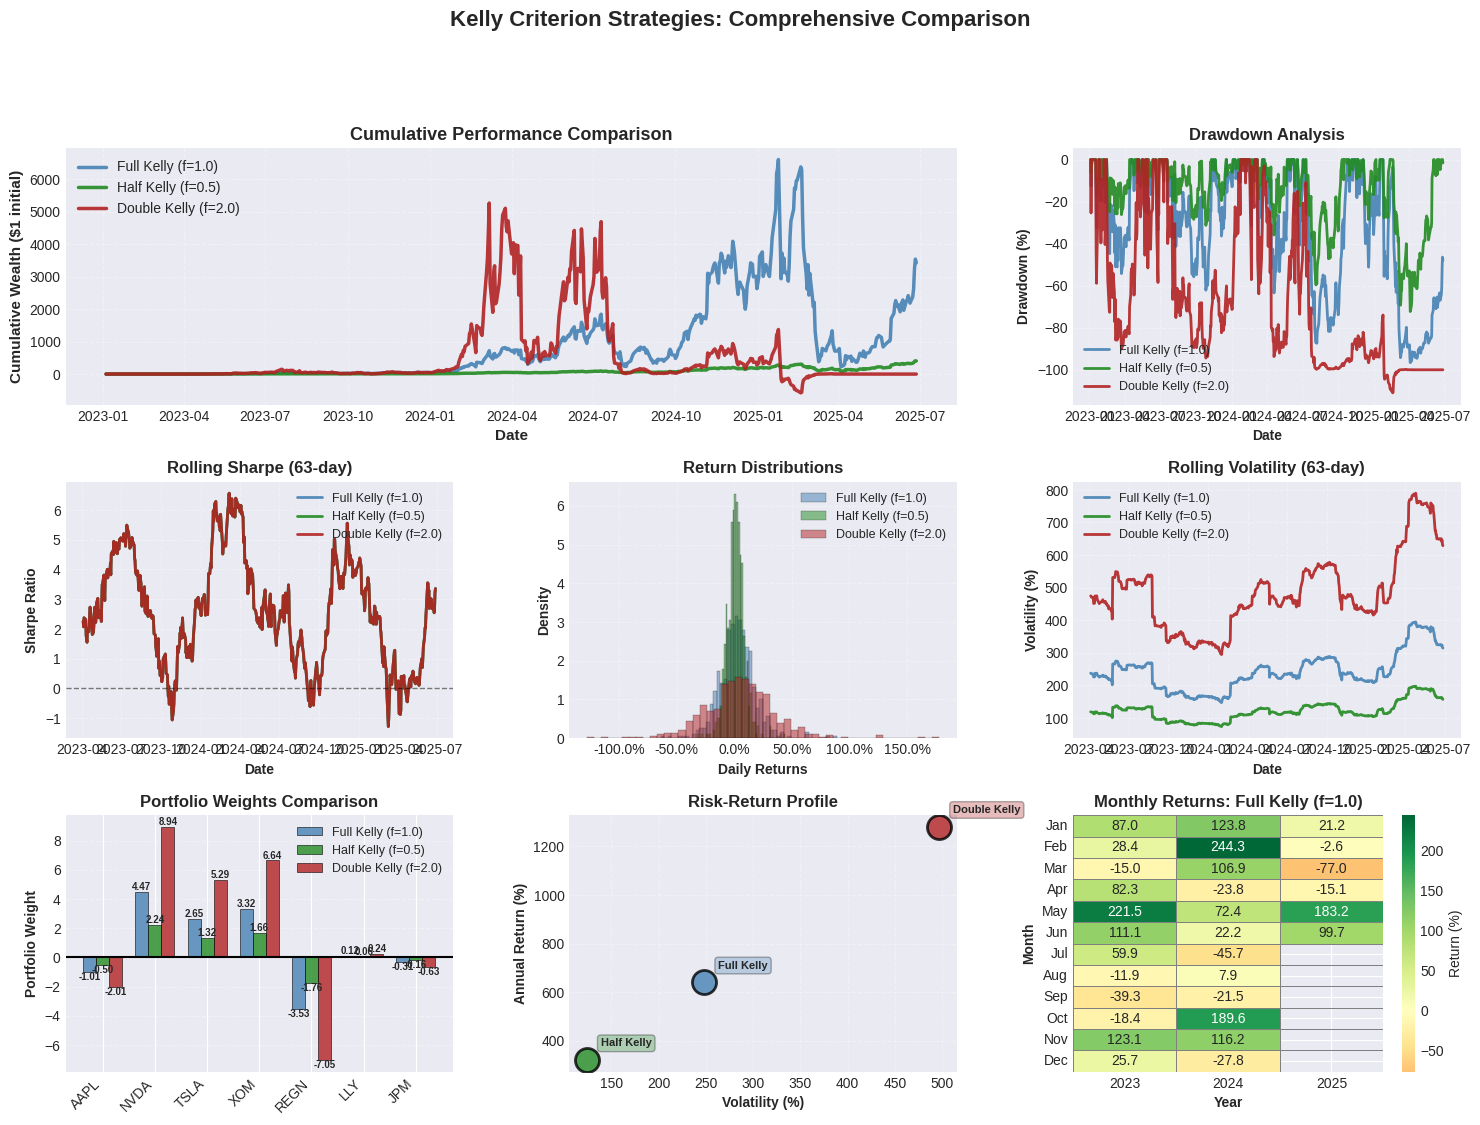


KELLY CRITERION ANALYSIS AND RECOMMENDATIONS

When Each Strategy Outperformed:

1. FULL KELLY (f=1.0) - Theoretical Optimum:
   Best For:
   • Long-term investors (10+ years)
   • High risk tolerance
   • Maximizing long-run growth rate
   Performance:
   • Sharpe Ratio: 2.5602
   • Max Drawdown: -96.59%
   Caution:
   • Can experience severe drawdowns (30-50%)
   • Requires discipline to stay invested

2. HALF KELLY (f=0.5) - Conservative Growth:
   Best For:
   • Moderate risk tolerance
   • Seeking balance between growth and stability
   • Most practitioners' recommendation
   Performance:
   • Sharpe Ratio: 2.5441
   • Max Drawdown: -72.30%
   Advantages:
   • Achieves ~75% of full Kelly growth
   • Roughly half the volatility
   • More psychologically sustainable

3. DOUBLE KELLY (f=2.0) - Aggressive:
   Best For:
   • Professional traders with stop-losses
   • Very high risk tolerance
   • Short-term tactical positions
   Performance:
   • Sharpe Ratio: 2.5682
   • Max Drawdown:

In [12]:
# ========================================================================
# PART 4: KELLY CRITERION (Execution)
# ========================================================================

print("\n" + "#"*80)
print("# PART 4: KELLY CRITERION STRATEGIES")
print("#"*80)

kelly_strategies, kelly_comparison_df = compare_kelly_strategies(
    returns, TICKERS, RISK_FREE_RATE
)

kelly_weights_df = create_kelly_weights_table(kelly_strategies, TICKERS)

print("\nKelly Criterion Weights:")
print(kelly_weights_df.round(4).to_string())

print("\n\nPerformance Comparison:")
kelly_display = kelly_comparison_df.copy()
kelly_display['Annual Return'] = kelly_display['Annual Return'].apply(lambda x: f"{x:.2%}")
kelly_display['Annual Volatility'] = kelly_display['Annual Volatility'].apply(lambda x: f"{x:.2%}")
kelly_display['Sharpe Ratio'] = kelly_display['Sharpe Ratio'].apply(lambda x: f"{x:.4f}")
kelly_display['Max Drawdown'] = kelly_display['Max Drawdown'].apply(lambda x: f"{x:.2%}")
kelly_display['Total Leverage'] = kelly_display['Total Leverage'].apply(lambda x: f"{x:.2f}x")
kelly_display['Long Exposure'] = kelly_display['Long Exposure'].apply(lambda x: f"{x:.2%}")
kelly_display['Short Exposure'] = kelly_display['Short Exposure'].apply(lambda x: f"{x:.2%}")
kelly_display['Net Exposure'] = kelly_display['Net Exposure'].apply(lambda x: f"{x:.2%}")
kelly_display['Skewness'] = kelly_display['Skewness'].apply(lambda x: f"{x:.3f}")
kelly_display['Excess Kurtosis'] = kelly_display['Excess Kurtosis'].apply(lambda x: f"{x:.3f}")
kelly_display['VaR (95%)'] = kelly_display['VaR (95%)'].apply(lambda x: f"{x:.2%}")
print(kelly_display.to_string(index=False))

kelly_weights_df.to_csv('kelly_criterion_weights.csv')
kelly_comparison_df.to_csv('kelly_criterion_performance.csv', index=False)
print("\n  Saved: kelly_criterion_weights.csv")
print("  Saved: kelly_criterion_performance.csv")

print("\nGenerating Kelly Criterion visualizations...")
plot_kelly_comparison(returns, kelly_strategies, TICKERS,
                     filename="kelly_criterion_comprehensive_analysis.png")

print(f"\n{'='*80}")
print("KELLY CRITERION ANALYSIS AND RECOMMENDATIONS")
print(f"{'='*80}")

full_kelly_sharpe = kelly_comparison_df[kelly_comparison_df['Strategy'] == 'Full Kelly (f=1.0)']['Sharpe Ratio'].values[0]
half_kelly_sharpe = kelly_comparison_df[kelly_comparison_df['Strategy'] == 'Half Kelly (f=0.5)']['Sharpe Ratio'].values[0]
double_kelly_sharpe = kelly_comparison_df[kelly_comparison_df['Strategy'] == 'Double Kelly (f=2.0)']['Sharpe Ratio'].values[0]
full_kelly_dd = kelly_comparison_df[kelly_comparison_df['Strategy'] == 'Full Kelly (f=1.0)']['Max Drawdown'].values[0]
half_kelly_dd = kelly_comparison_df[kelly_comparison_df['Strategy'] == 'Half Kelly (f=0.5)']['Max Drawdown'].values[0]
double_kelly_dd = kelly_comparison_df[kelly_comparison_df['Strategy'] == 'Double Kelly (f=2.0)']['Max Drawdown'].values[0]

print("\nWhen Each Strategy Outperformed:\n")
print("1. FULL KELLY (f=1.0) - Theoretical Optimum:")
print("   Best For:\n   • Long-term investors (10+ years)\n   • High risk tolerance\n   • Maximizing long-run growth rate")
print(f"   Performance:\n   • Sharpe Ratio: {full_kelly_sharpe:.4f}\n   • Max Drawdown: {full_kelly_dd:.2%}")
print("   Caution:\n   • Can experience severe drawdowns (30-50%)\n   • Requires discipline to stay invested\n")
print("2. HALF KELLY (f=0.5) - Conservative Growth:")
print("   Best For:\n   • Moderate risk tolerance\n   • Seeking balance between growth and stability\n   • Most practitioners' recommendation")
print(f"   Performance:\n   • Sharpe Ratio: {half_kelly_sharpe:.4f}\n   • Max Drawdown: {half_kelly_dd:.2%}")
print("   Advantages:\n   • Achieves ~75% of full Kelly growth\n   • Roughly half the volatility\n   • More psychologically sustainable\n")
print("3. DOUBLE KELLY (f=2.0) - Aggressive:")
print("   Best For:\n   • Professional traders with stop-losses\n   • Very high risk tolerance\n   • Short-term tactical positions")
print(f"   Performance:\n   • Sharpe Ratio: {double_kelly_sharpe:.4f}\n   • Max Drawdown: {double_kelly_dd:.2%}")
print("   Caution:\n   • Extreme volatility\n   • Can lead to ruin if unlucky\n   • Generally NOT recommended\n")

best_strategy = kelly_comparison_df.loc[kelly_comparison_df['Sharpe Ratio'].idxmax(), 'Strategy']
print(f"{'─'*80}")
print(f"RECOMMENDATION: {best_strategy}")
print(f"{'─'*80}")
if 'Half' in best_strategy:
    print("\nHalf-Kelly is recommended for most investors:\n  • Best risk-adjusted returns\n  • Manageable drawdowns\n  • Proven in academic literature\n  • Used by successful practitioners (Buffett, Munger)")

**Final Summary**

In [13]:
# ========================================================================
# FINAL SUMMARY AND CONCLUSIONS
# ========================================================================

print("\n" + "="*80)
print("FINAL SUMMARY AND RECOMMENDATIONS")
print("="*80)

print("\nPORTFOLIO ALLOCATION STRATEGIES COMPARED:")

summary_data = {
    'Strategy': [
        'MVO (No Short)',
        'MVO (20% Cap)',
        'MVO (Short Allowed)',
        'Black-Litterman',
        'Half-Kelly',
        '1/N Equal Weight'
    ],
    'Sharpe Ratio': [
        f"{step1_result['sharpe']:.4f}",
        f"{step2_result['sharpe']:.4f}",
        f"{step3_result['sharpe']:.4f}",
        f"{bl_result['sharpe']:.4f}",
        f"{half_kelly_sharpe:.4f}",
        "N/A (varies)"
    ],
    'Complexity': [
        'Medium',
        'Medium',
        'High',
        'High',
        'High',
        'Low'
    ],
    'Recommended For': [
        'Most retail investors',
        'Institutional mandates',
        'Sophisticated hedge funds',
        'Asset managers with views',
        'Growth-focused investors',
        'Beginners, benchmarking'
    ]
}

summary_df = pd.DataFrame(summary_data)
print("\n" + summary_df.to_string(index=False))

print("\n\nKEY TAKEAWAYS:")
print("  1. Diversification constraints (20% cap) reduce concentration risk")
print("  2. Short selling increases Sharpe ratio but adds complexity and cost")
print("  3. MVO vs 1/N: Context-dependent; 1/N is robust to estimation error")
print("  4. Black-Litterman effectively incorporates analyst views")
print("  5. Half-Kelly provides best risk-adjusted growth for most investors")

print("\n\nFINAL RECOMMENDATION:")
print("  For a typical client seeking strong risk-adjusted returns:")
print(f"  -> Start with MVO (20% cap) as baseline")
print(f"     Expected Return: {step2_result['return']:.2%}")
print(f"     Volatility: {step2_result['volatility']:.2%}")
print(f"     Sharpe Ratio: {step2_result['sharpe']:.4f}")
print(f"  -> Consider Black-Litterman when strong views available")
print(f"  -> Use Half-Kelly for aggressive growth with acceptable risk")

print("\n" + "="*80)
print("ANALYSIS COMPLETE - All results saved to CSV and PNG files")
print("="*80)

output_files = [
    'correlation_heatmap.png',
    'efficient_frontier.png',
    'portfolio_weights_comparison.csv',
    'portfolio_metrics_comparison.csv',
    'mvo_vs_1n_simulation_results.csv',
    'mvo_vs_1n_statistical_analysis.csv',
    'mvo_vs_1n_comprehensive_analysis.png',
    'black_litterman_comparison.csv',
    'kelly_criterion_weights.csv',
    'kelly_criterion_performance.csv',
    'kelly_criterion_comprehensive_analysis.png'
]

print("\nOutput Files Generated:")
for f in output_files:
    print(f"  * {f}")

print("\n\n" + "="*80)
print("Thank you for using the Enhanced Portfolio Management System!")
print("All results have been saved and are ready for your report.")
print("="*80)


FINAL SUMMARY AND RECOMMENDATIONS

PORTFOLIO ALLOCATION STRATEGIES COMPARED:

           Strategy Sharpe Ratio Complexity           Recommended For
     MVO (No Short)       2.2528     Medium     Most retail investors
      MVO (20% Cap)       1.9782     Medium    Institutional mandates
MVO (Short Allowed)       2.4842       High Sophisticated hedge funds
    Black-Litterman       5.8063       High Asset managers with views
         Half-Kelly       2.5441       High  Growth-focused investors
   1/N Equal Weight N/A (varies)        Low   Beginners, benchmarking


KEY TAKEAWAYS:
  1. Diversification constraints (20% cap) reduce concentration risk
  2. Short selling increases Sharpe ratio but adds complexity and cost
  3. MVO vs 1/N: Context-dependent; 1/N is robust to estimation error
  4. Black-Litterman effectively incorporates analyst views
  5. Half-Kelly provides best risk-adjusted growth for most investors


FINAL RECOMMENDATION:
  For a typical client seeking strong risk-adjuste